[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab5/lab5.ipynb)
# Práctica 5: Optimización de redes neuronales


En este laboratorio trabajaremos con el mismo conjunto de datos que hemos utilizado hasta ahora. Carga todo el conjunto en un solo dataloader (en este laboratorio solo nos ocuparemos de estudiar el ajuste en entrenamiento, no la generalización).

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import numpy as np
import seaborn as sns
import pandas as pd
import torch

# TODO - Carga los datos
def load_titanic(batch_size = 32) :
  # Cargamos el dataset Titanic desde seaborn
  df = sns.load_dataset('titanic')

  # Selección de variables relevantes y limpieza
  # Columnas que vamos a usar
  cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']
  df = df[cols].copy()

  # Eliminamos filas con valores faltantes
  df = df.dropna(subset=['age', 'embarked', 'fare'])

  # Separar etiquetas y características
  y = df['survived'].to_numpy().astype(np.float32) # etiquetas como float
  X = df.drop(columns=['survived'])

  # One-hot encoding para todas las variables categóricas
  categorical_cols = ['pclass', 'sex', 'embarked', 'alone']
  X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

  # Estandarizar las variables numericas
  # solo pone primero a las numericas
  numeric_cols = ['age', 'sibsp', 'parch', 'fare']
  X_numeric = X_encoded[numeric_cols + [c for c in X_encoded.columns if c not in numeric_cols]].copy()

  scaler = StandardScaler().fit(X_numeric[numeric_cols]) # Objeto que normaliza
  X_numeric[numeric_cols] = scaler.transform(X_numeric[numeric_cols])

  # Convertir a numpy arrays
  X_np = X_numeric.to_numpy().astype(np.float32)
  y_np = y.reshape(-1, 1).astype(np.float32)  # reshape(numero de muestras como de filas, 1 unica columna)

  # Convertir a Data Loader
  ds = torch.utils.data.TensorDataset(torch.from_numpy(X_np), torch.from_numpy(y_np))
  dl = DataLoader(ds, batch_size = batch_size, shuffle = True)
  return dl

Usaremos la misma arquitectura, función para el aprendizaje, función para evaluación y función de coste que en los laboratorios anteriores. Haz las declaraciones necesarias en la siguiente celda.

Adapta la función `train_model` para que el parámetro `val_loader` pueda ser `None`, en cuyo caso no se calcula la pérdida en validación y se devuelve una lista vacía en la segunda componente de la tupla.

In [7]:
# TODO - Declara las funciones, la arquitectura y la función de pérdida a utilizar
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torch

class FullyConnected(nn.Module) :
  def __init__(self, input_dim, output_dim) :
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 20)
    self.fc2 = nn.Linear(20, 10)
    self.fc3 = nn.Linear(10, 5)
    self.out = nn.Linear(5, output_dim)

  def forward(self, x) :
    h0 = torch.relu(self.fc1(x))
    h1 = torch.relu(self.fc2(h0))
    h2 = torch.relu(self.fc3(h1))
    y = torch.sigmoid(self.out(h2))# sigmoide para obtener probabilidad (BCELoss)

    return y

def measure_model(model:nn.Module, loss_fn:nn.modules.loss._Loss, data_loader:data.DataLoader) -> tuple[float, float]:
    #TODO Completa la función
    model.eval() # Pone el modelo en modo evaluacion para que se comporte de manera consistente
    loss = 0
    accuracy = 0

    # Bucle de evaluación
    with torch.no_grad(): # No calculamos gradientes
      for inputs, targets in data_loader:
          outputs = model(inputs) # pasamos los datos de entrada por el modelo
          loss += loss_fn(outputs, targets).item() # suma la perdida de esta iteracion
          # .item() en NumPy y PyTorch devuelven como int o float de python
          accuracy += (outputs.round() == targets).sum().item() / len(targets) # Suma el accuracy en los targets de la iteración
    # Promedia los resultados
    loss /= len(data_loader)
    accuracy /= len(data_loader)

    return loss, accuracy

def train_model(model:nn.Module, optimizer:optim.Optimizer, train_loader:data.DataLoader,
                loss_fn:nn.modules.loss._Loss, num_epochs:int, val_loader:data.DataLoader = None,
                scheduler = None, print_data = True) -> tuple[tuple[list[int], list[int]]]:

    #TODO Completa la función

    train_loss = None # inicializo la variable que almacenará la pérdida
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):

      model.train() # Pone el modelo en modo entrenamiento
      epoch_loss = 0 # almacena las perdidas de cada elemento

      for inputs, targets in train_loader:
        # Inicializo los gradientes a 0 para que no se acumulen
        optimizer.zero_grad()

        outputs = model(inputs)
        train_loss = loss_fn(outputs, targets)

        # Calcula el gradiente de la pérdida respecto a cada parámetro del modelo
        train_loss.backward()
        # Actualiza los pesos
        optimizer.step()



        epoch_loss += train_loss.item()

      # perdida media del epoch
      epoch_loss /= len(train_loader)
      train_losses.append(epoch_loss)
      current_lr = optimizer.param_groups[0]["lr"] # Learning rate usado en esta epoch
      if print_data :
        print(f"Epoch {epoch + 1}/{num_epochs}, Train loss: {epoch_loss:.3f}, Learning Rate (this epoch): {lr}")

      # En caso de poner un conjunto de entrenamiento
      if val_loader is not None:
        # Pérdida sobre todo el conjunto de validación (modo eval y sin gradientes)
        val_loss, _ = measure_model(model, loss_fn, val_loader)
        val_losses.append(val_loss)
        if print_data :
          print(f"Epoch {epoch + 1}/{num_epochs}, Validation loss: {val_loss:.3f}")

      # El scheduler se actualiza al final de cada epoch, después de optimizer.step()
      if scheduler is not None:
        scheduler.step()

    return train_losses, val_losses

Con todo esto listo, haremos una comparativa de los distintos optimizadores que nos ofrece `torch`.

En primer lugar haremos un entrenamiento con un optimizador SGD sin momentum. Instancia el modelo y un optimizador `optim.SGD`. Haz el entrenamiento y muestra la curva de aprendizaje. Prueba distintos valores de *learning rate*. Guarda las curvas de aprendizaje en un diccionario para mostrarlas todas en un mismo gráfico.

Epoch 1/100, Train loss: 0.678, Learning Rate (this epoch): 0.1
Epoch 2/100, Train loss: 0.672, Learning Rate (this epoch): 0.1
Epoch 3/100, Train loss: 0.675, Learning Rate (this epoch): 0.1
Epoch 4/100, Train loss: 0.673, Learning Rate (this epoch): 0.1
Epoch 5/100, Train loss: 0.678, Learning Rate (this epoch): 0.1
Epoch 6/100, Train loss: 0.673, Learning Rate (this epoch): 0.1
Epoch 7/100, Train loss: 0.679, Learning Rate (this epoch): 0.1
Epoch 8/100, Train loss: 0.673, Learning Rate (this epoch): 0.1
Epoch 9/100, Train loss: 0.673, Learning Rate (this epoch): 0.1
Epoch 10/100, Train loss: 0.673, Learning Rate (this epoch): 0.1
Epoch 11/100, Train loss: 0.674, Learning Rate (this epoch): 0.1
Epoch 12/100, Train loss: 0.677, Learning Rate (this epoch): 0.1
Epoch 13/100, Train loss: 0.674, Learning Rate (this epoch): 0.1
Epoch 14/100, Train loss: 0.672, Learning Rate (this epoch): 0.1
Epoch 15/100, Train loss: 0.671, Learning Rate (this epoch): 0.1
Epoch 16/100, Train loss: 0.675, L

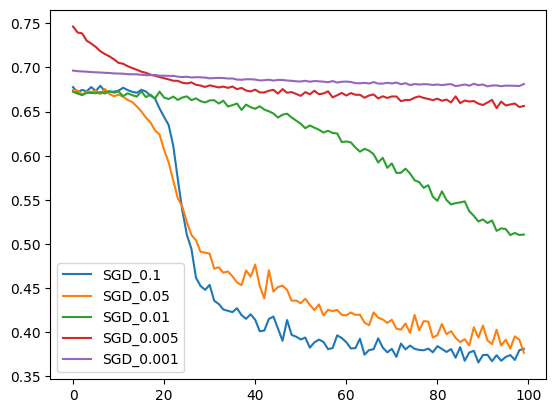

In [8]:
import matplotlib.pyplot as pyplot

dataLoader = load_titanic()
EPOCHS = 100
LOSS = nn.BCELoss()
lrs_a_explorar = [0.1, 5e-2, 1e-2, 5e-3, 1e-3] # TODO - Cambia esta lista para incluir los valores que consideres
histories = {}
n_cols = dataLoader.dataset.tensors[0].shape[1]

for lr in lrs_a_explorar:
    model = FullyConnected(n_cols, 1)
    optimizer = optim.SGD(model.parameters(), lr = lr)
    train_losses, _ = train_model(model, optimizer, dataLoader, LOSS, EPOCHS)
    train_accuracy = measure_model(model, LOSS, dataLoader)[1]

    # TODO: Guarda el history del entrenamiento
    histories[f'SGD_{lr}'] = {'loss_history': train_losses, 'accuracy_history': train_accuracy}

# Mostramos en gráficas las curvas de aprendizaje que tengamos acumuladas en histories
for k in histories:
    pyplot.plot(histories[k]['loss_history'], label=k)
pyplot.legend()
pyplot.show()

## Comparativas

Repite todo el proceso de entrenamiento realizando cada uno de estos cambios. Haz varias pruebas hasta encontrar valores adecuados. No resetees el kernel ni vuelvas a ejecutar las dos primeras celdas entre las distintas pruebas, o perderás la posibilidad de comparar las curvas de aprendizaje. Recuerda modificar la etiqueta de la curva de cada prueba en la gráfica cuando añadas registros a `histories`.

1. **Tamaño del lote**: Modifica el tamaño de lote al crear el dataloader y compara los resultados
1. **Learning rate variable**: Vuelve sobre la celda en la que se declara el optimizador y utiliza un [scheduler](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate) para que el *learning rate* vaya decayendo linealmente con el tiempo. Utiliza los consejos vistos en teoría para elegir los parámetros. Tendrás que modificar tu función de aprendizaje para que acepte el `scheduler` como parámetro y que llame a su método `step` cuando sea necesario. También es útil mostrar por pantalla el *learning rate* en cada epoch.
1. **Uso de momentum**: Vuelve sobre la celda en la que se declara el optimizador y configúralo para que utilice momentum. Consulta los apuntes y la [documentación](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html#sgd) para ayudarte a elegir los hiperparámetros
1. **Otros optimizadores**: Ayúdate de la [documentación](https://docs.pytorch.org/docs/stable/optim.html#algorithms) para probar RMSProp, Adagrad y Adam y compara con los resultados obtenidos hasta ahora.


Comparamos el tamaño del lote: ####################


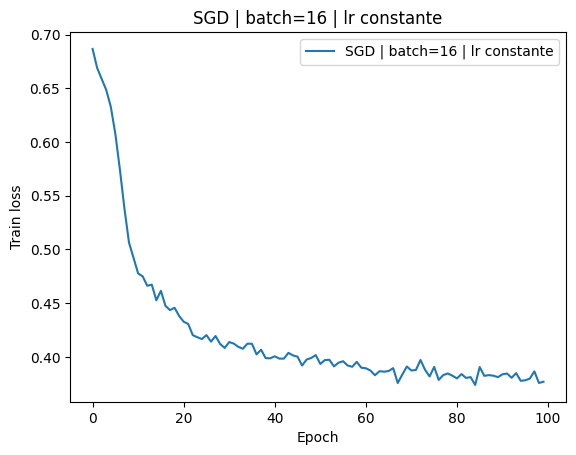

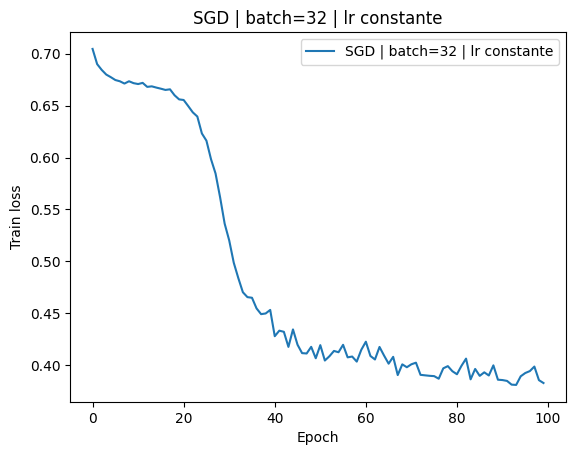

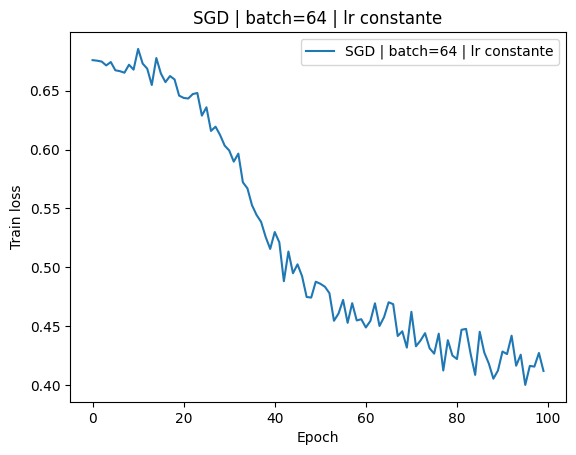


 ################################################## 

Comparamos learning rate fijo y variable: ####################


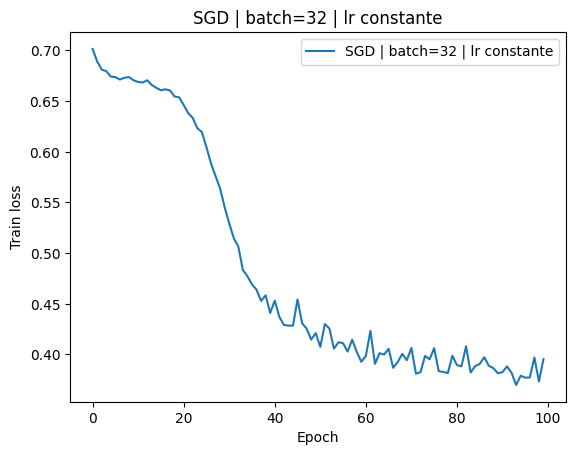

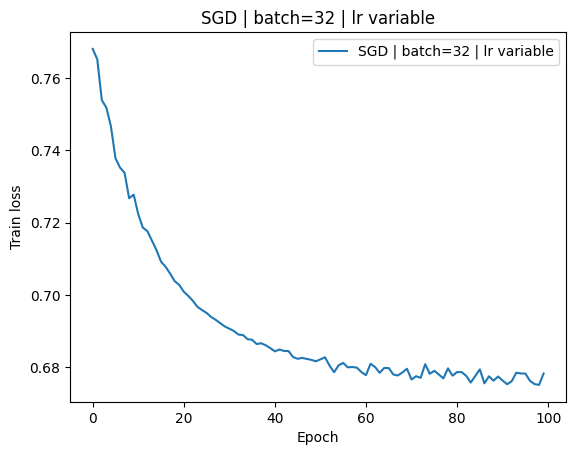


 ################################################## 

Comparamos el uso de Momentum en SGD: ####################


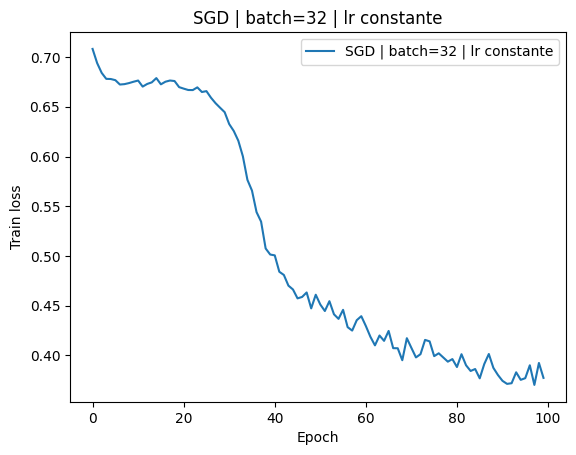

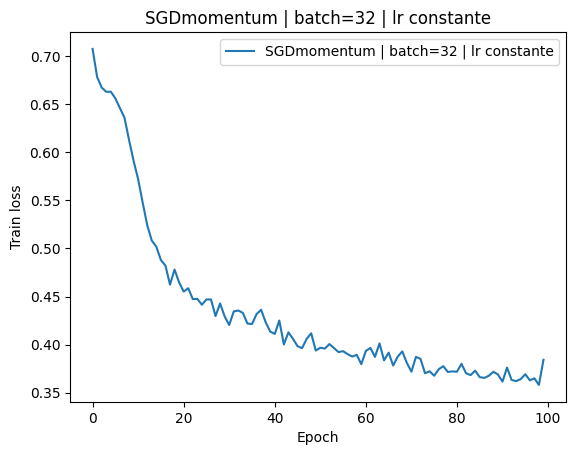


 ################################################## 

Comparamos optimizadores: ####################


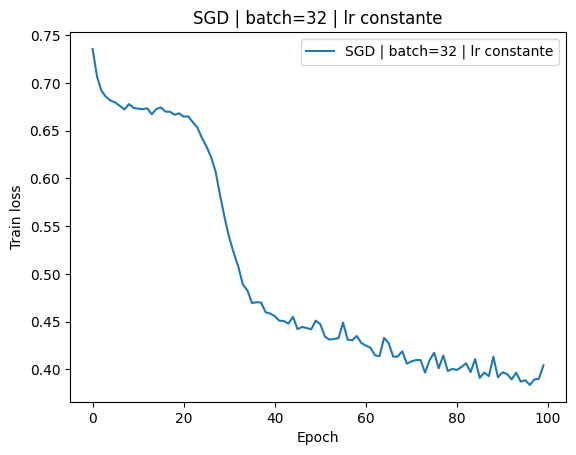

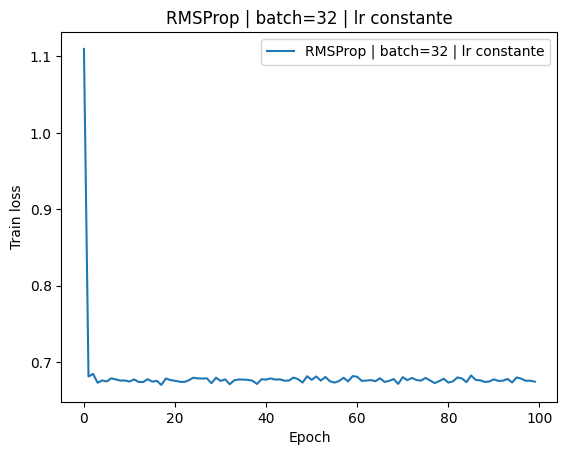

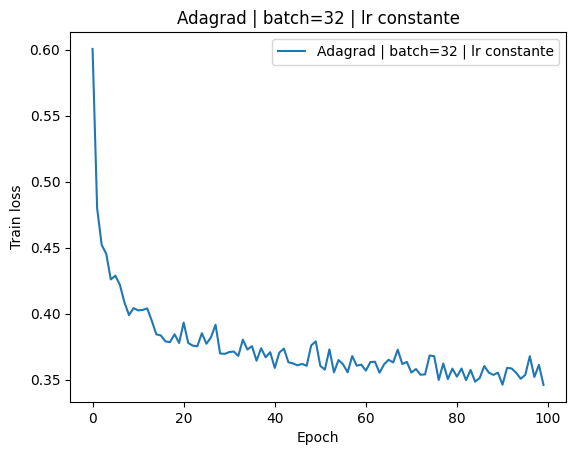

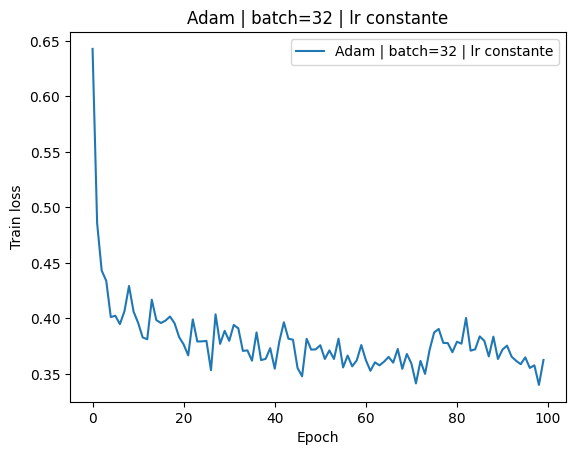


 ################################################## 



In [9]:
def comparativa(optimizer_name = "SGD", batch_size = 32, lr = False) -> None:
  """
  Ejecuta una revisión del entrenamiento cambiando algunos parámetros, siempre 100 epochs
  lr = True -> Learning rate variable con el tiempo
  Los valores aceptados para optim son:
  "SGD", "SGDmomentum", "RMSProp", "Adagrad", "Adam"
  """
  # Variables asumidas
  EPOCHS = 100
  LOSS = nn.BCELoss()

  dataLoader = load_titanic(batch_size)
  n_cols = dataLoader.dataset.tensors[0].shape[1]

  model = FullyConnected(n_cols, 1)

  # Seleccion del optimizador
  lr_inicial = 5e-2
  alfa = 0.5 #; alfa = 0.9 ; alfa = 0.99 # valores tipicos para momentum
  epsilon = 1e-8 #; epsilon = 1e-4 # si se sube se comporta como SGD con momentum
  # Diccionario de funciones que no llama a todas las funciones al crearse
  optimizers = {
      "SGD":         lambda p: optim.SGD(p, lr=lr_inicial),
      "SGDmomentum": lambda p: optim.SGD(p, lr=lr_inicial, momentum=alfa),
      "RMSProp":     lambda p: optim.RMSprop(p, lr=lr_inicial, eps=epsilon),
      "Adagrad":     lambda p: optim.Adagrad(p, lr=lr_inicial),
      "Adam":        lambda p: optim.Adam(p, lr=lr_inicial),
  }
  ####################################
  if optimizer_name not in optimizers:
    raise ValueError(f"No valid optimizer: {optimizer_name}. Options: {list(optimizers)}")
  ####################################
  optim_fun = optimizers[optimizer_name](model.parameters())

  # Seleccion del Learning Rate
  scheduler = None

  if lr:
    scheduler = torch.optim.lr_scheduler.LinearLR(optim_fun, start_factor=0.1, end_factor=1e-4, total_iters=EPOCHS)

  train_losses, _ = train_model(model, optim_fun, dataLoader, LOSS, EPOCHS, scheduler = scheduler, print_data = False)

  # Etiqueta con la configuración usada
  etiqueta = f"{optimizer_name} | batch={batch_size} | lr {'variable' if lr else 'constante'}"

  pyplot.plot(train_losses, label=etiqueta)
  pyplot.title(etiqueta)
  pyplot.xlabel("Epoch")
  pyplot.ylabel("Train loss")
  pyplot.legend()
  pyplot.show()

  return None

## 1 Tamaño del lote
print("Comparamos el tamaño del lote:", "#"*20)
comparativa(batch_size = 16)
comparativa() # 32
comparativa(batch_size = 64)
print("\n", "#"*50, "\n")

## 2 Comprobamos la diferencia entre el learning rate fijo y variable:
print("Comparamos learning rate fijo y variable:", "#"*20)
comparativa(lr = False)
comparativa(lr = True)
print("\n", "#"*50, "\n")

## 3 Comprobamos la diferencia entre usar y no usar momentum
print("Comparamos el uso de Momentum en SGD:", "#"*20)
comparativa()
comparativa(optimizer_name = "SGDmomentum")
print("\n", "#"*50, "\n")

## 4 Comprobamos la diferencia entre optimizadores
print("Comparamos optimizadores:", "#"*20)
for comp in ["SGD", "RMSProp", "Adagrad", "Adam"]:
  comparativa(optimizer_name = comp)
print("\n", "#"*50, "\n")